In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D4/'

In [2]:
df_flat = pd.read_csv(main_dir + 'faiss_flat.csv')
df_flat['index'] = 'flat'
df_hnsw = pd.read_csv(main_dir + 'faiss_hnsw.csv')
df_hnsw['index'] = 'hnsw'
df_lsh = pd.read_csv(main_dir + 'faiss_lsh.csv')
df_lsh['index'] = 'lsh'

In [3]:
result = pd.DataFrame()
dfs = [df_flat, df_hnsw, df_lsh]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,2272,1,95.16,97.65,96.39,2162,110,2582,52,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,4544,2,48.33,99.19,64.99,2196,2348,2616,18,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,6816,3,32.28,99.37,48.73,2200,4616,2620,14,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,9088,4,24.26,99.59,39.02,2205,6883,2625,9,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,11360,5,19.42,99.64,32.50,2206,9154,2626,8,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,13632,6,16.09,99.10,27.69,2194,11438,2614,20,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,15904,7,13.80,99.10,24.22,2194,13710,2614,20,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,18176,8,12.08,99.19,21.54,2196,15980,2616,18,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,20448,9,10.75,99.28,19.40,2198,18250,2618,16,lsh,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    960
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    960
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    960
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    960
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    960
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
17    30
18    30
19    30
20    30
21    30
22    30
23    30
24    30
25    30
26    30
27    30
28    30
29    30
30    30
31    30
32    30
Name: count, dtype: int64

In [10]:
valid_rows = result[result['Recall %']>=80]
valid_rows

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,2272,1,95.16,97.65,96.39,2162,110,2582,52,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,4544,2,48.33,99.19,64.99,2196,2348,2616,18,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,6816,3,32.28,99.37,48.73,2200,4616,2620,14,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,9088,4,24.26,99.59,39.02,2205,6883,2625,9,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,11360,5,19.42,99.64,32.50,2206,9154,2626,8,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,13632,6,16.09,99.10,27.69,2194,11438,2614,20,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,15904,7,13.80,99.10,24.22,2194,13710,2614,20,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,18176,8,12.08,99.19,21.54,2196,15980,2616,18,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,20448,9,10.75,99.28,19.40,2198,18250,2618,16,lsh,[title],1024,0,32,salted_qgrams,,4


In [11]:
valid_rows['index'].value_counts()

index
flat    320
lsh     320
hnsw    290
Name: count, dtype: int64

In [12]:
max_f1 = valid_rows.loc[valid_rows.groupby(['num_hashes','index'])['F1 %'].idxmax()]
max_f1

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,2272,1,95.16,97.65,96.39,2162,110,2582,52,flat,[title],1024,0,1,salted_qgrams,,4
320,FAISS HNSW Blocking,2272,1,84.60,86.81,85.69,1922,350,2342,292,hnsw,[title],1024,0,1,salted_qgrams,,4
640,FAISS LSH Blocking,2272,1,95.25,97.74,96.48,2164,108,2584,50,lsh,[title],1024,0,1,salted_qgrams,,4
10,FAISS FLAT Blocking,2272,1,95.16,97.65,96.39,2162,110,2582,52,flat,[title],1024,0,2,salted_qgrams,,4
330,FAISS HNSW Blocking,2272,1,86.05,88.30,87.16,1955,317,2375,259,hnsw,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
930,FAISS LSH Blocking,2272,1,95.03,97.52,96.26,2159,113,2579,55,lsh,[title],1024,0,30,salted_qgrams,,4
300,FAISS FLAT Blocking,2272,1,94.89,97.38,96.12,2156,116,2576,58,flat,[title],1024,0,31,salted_qgrams,,4
940,FAISS LSH Blocking,2272,1,94.98,97.47,96.21,2158,114,2578,56,lsh,[title],1024,0,31,salted_qgrams,,4
310,FAISS FLAT Blocking,2272,1,94.89,97.38,96.12,2156,116,2576,58,flat,[title],1024,0,32,salted_qgrams,,4


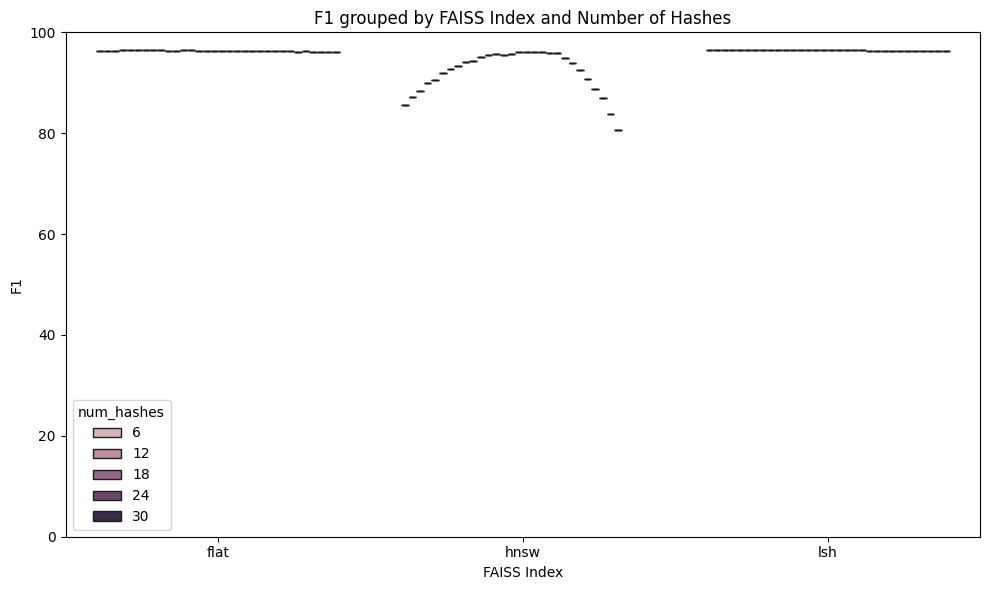

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="index",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by FAISS Index and Number of Hashes")
plt.xlabel("FAISS Index")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [14]:
metrics_df = max_f1.melt(
    id_vars=["index", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,index,num_hashes,Metric,Score
0,flat,1,Precision %,95.16
1,hnsw,1,Precision %,84.60
2,lsh,1,Precision %,95.25
3,flat,2,Precision %,95.16
4,hnsw,2,Precision %,86.05
...,...,...,...,...
274,lsh,30,F1 %,96.26
275,flat,31,F1 %,96.12
276,lsh,31,F1 %,96.21
277,flat,32,F1 %,96.12


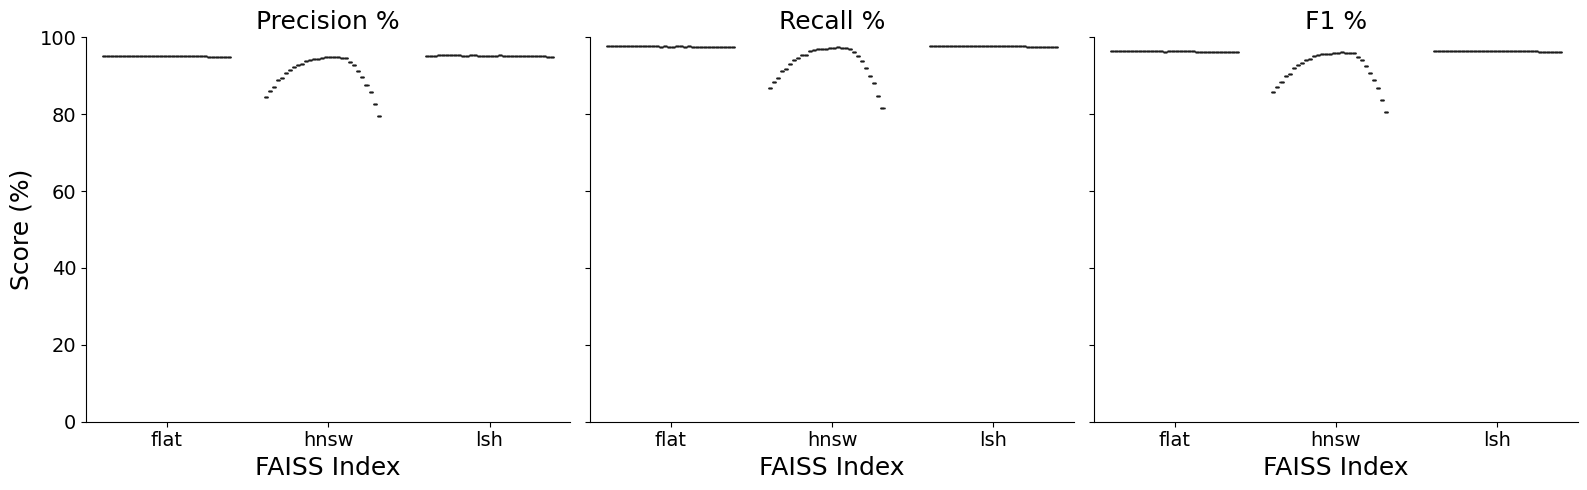

In [15]:
g = sns.catplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("FAISS Index", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

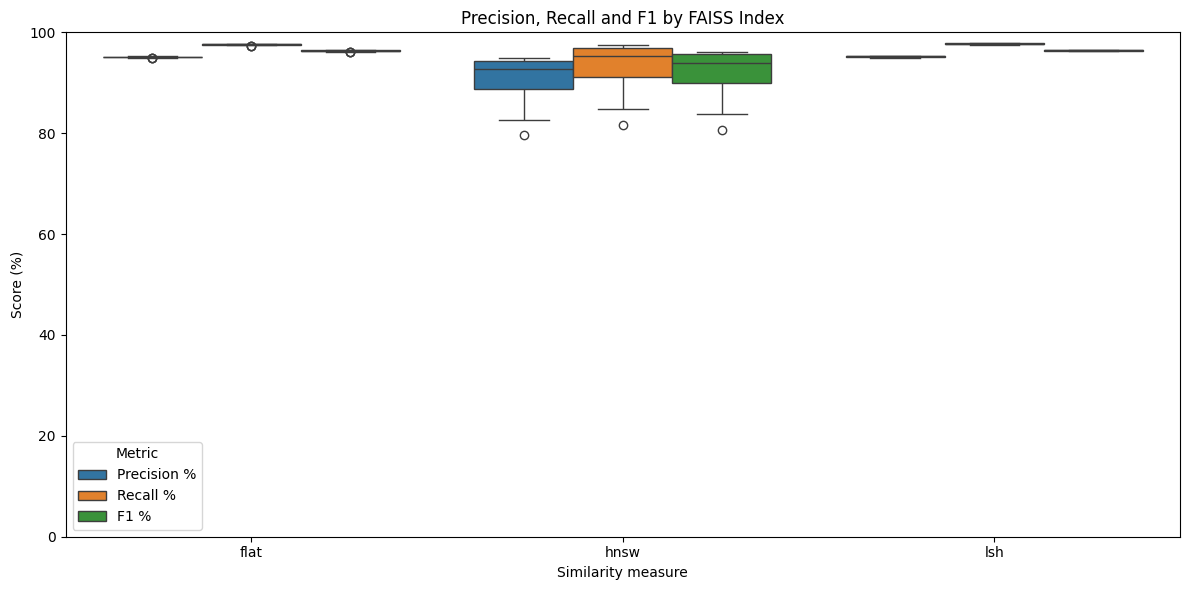

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by FAISS Index")
plt.xlabel("FAISS Index")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()